# Task 3 — Cognitive load and data-ink

**Status:** all supplied-data analysis is executed. Human observations are deliberately unfilled. Run the interactive collection cell, use a real reader, then rerun the analysis cells below it. Blank responses are not evidence. No simulated results are used.

Charts use the object-oriented Matplotlib API. Experimental stimuli intentionally retain the supplied colours and omit titles where the brief requires this; they are displays for testing perception, not final explanatory charts.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Circle, Wedge
from IPython.display import display
DATA = Path('data'); RESULTS = Path('results'); FIGURES = Path('figures')
RESULTS.mkdir(exist_ok=True); FIGURES.mkdir(exist_ok=True)
SEED = 42
GREY = '#b9bdc3'; ACCENT = '#bd3f58'
plt.rcParams.update({'figure.dpi': 110, 'axes.titlesize': 12, 'axes.labelsize': 10})
def clean(ax):
    for side in ('top','right'): ax.spines[side].set_visible(False)
def save(fig, name):
    fig.savefig(FIGURES / name, dpi=300, bbox_inches='tight')


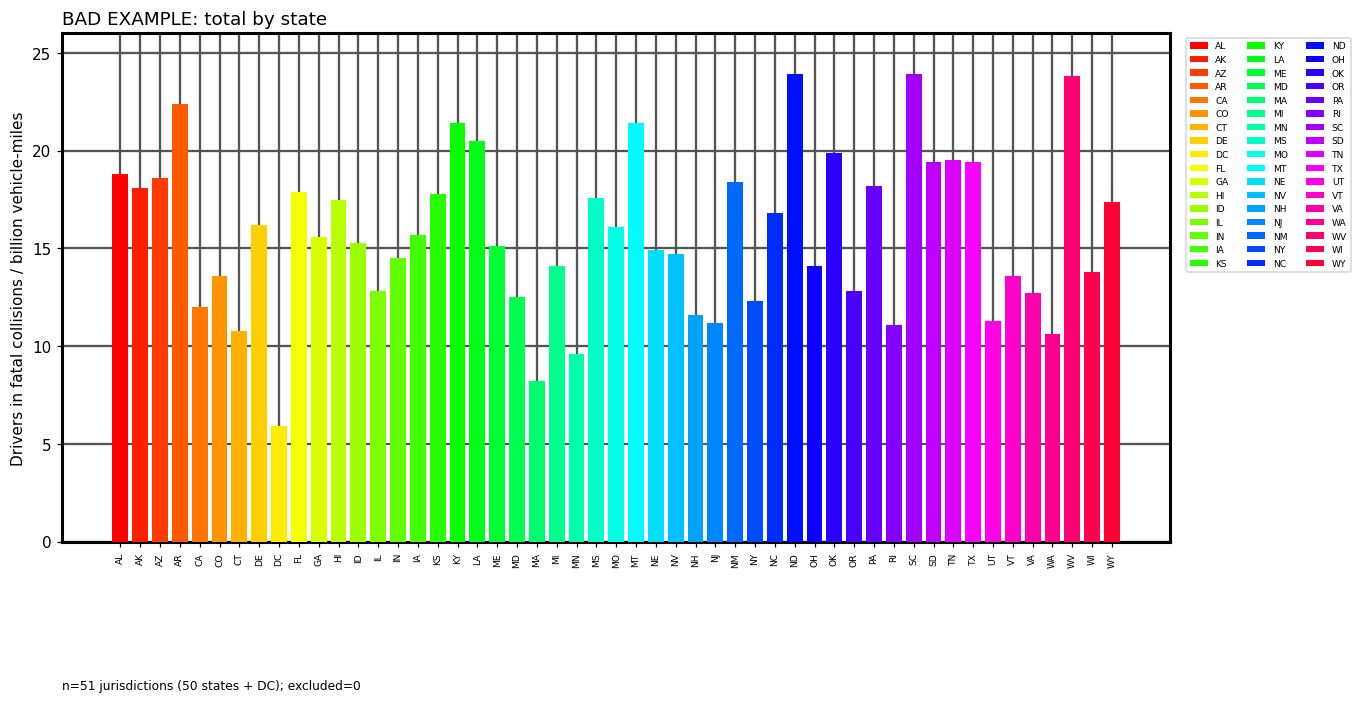

In [2]:
crashes=pd.read_csv(DATA/'car_crashes.csv')
assert len(crashes)==51 and crashes.total.notna().all()
def crash_bars(ax,stage=0):
    d=crashes.sort_values('total',ascending=False) if stage>=4 else crashes
    colours=[plt.colormaps['hsv'](i/51) for i in range(51)] if stage<3 else [GREY]*51
    bars=ax.bar(np.arange(51),d.total,color=colours,label=list(d.abbrev) if stage==0 else None,zorder=3)
    ax.set_ylim(0,26);ax.set_xticks(np.arange(51),d.abbrev,rotation=90,fontsize=6)
    ax.set_yticks(np.arange(0,26,5));ax.set_ylabel('Drivers in fatal collisions / billion vehicle-miles')
    ax.set_axisbelow(True);ax.grid(axis='both' if stage<2 else 'y',color='#555555' if stage<2 else '#e5e5e5',linewidth=1.5 if stage<2 else .5)
    if stage<2:
        for s in ax.spines.values():s.set_linewidth(2)
    else:
        for s in ax.spines.values():s.set_visible(False)
    if stage==0:ax.legend(ncol=3,fontsize=6,loc='upper left',bbox_to_anchor=(1.01,1))
    if stage>=5:
        bars[0].set_color(ACCENT);ax.set_xticks([0,50],[d.abbrev.iloc[0],d.abbrev.iloc[-1]],fontsize=9,rotation=0)
        ax.annotate(f'{d.abbrev.iloc[0]}: {d.total.iloc[0]:.1f}',(0,d.total.iloc[0]),xytext=(5,3),textcoords='offset points',fontsize=9)
    ax.text(0,-.29,'n=51 jurisdictions (50 states + DC); excluded=0',transform=ax.transAxes,fontsize=8)
    return bars
fig,ax=plt.subplots(figsize=(13,6));crash_bars(ax,0)
ax.set_title('BAD EXAMPLE: total by state',loc='left');save(fig,'task3_overloaded.png');plt.show()


**Overloaded chart:** length and aligned position encode the numeric rate correctly, but 51 nominal hues add no new variable and compete for attention. Similarity between each bar and its legend key invites 51 decoding operations. The boxed frame and two-direction grid consume attention; intrinsic load comes from comparing 51 rates. The deliberate bad example violates the one-pop-out rule by construction; no shadow is added because it would add another non-data mark.

| Element | Load | Why |
|---|---|---|
| 51 values, jurisdiction identities | Intrinsic | The comparison itself |
| 51 bar heights | Germane | Shows the rates |
| Zero baseline, numeric ticks, units | Germane | Enables correct decoding |
| 51 arbitrary colours | Extraneous | No additional meaning |
| 51-entry legend and handles | Extraneous | Duplicates x labels |
| 51 densely rotated x labels | Extraneous presentation of intrinsic identities | Crowding makes retrieval expensive |
| 51 vertical gridlines | Extraneous | Duplicate bar location |
| 6 heavy horizontal gridlines | Extraneous weight; potentially germane placement | Light guides would help instead |
| 4 thick spines | Extraneous | Full box not needed |
| Axis-naming title | Extraneous | No finding |
| Coverage note | Germane | Prevents scope ambiguity |

**Ink estimate, with working:** this is a mark-count proxy, not a literal pixel or area ratio. Numerator = 51 numerical bar marks. Denominator = 51 bars + 51 x tick-label text marks + 6 y tick-label text marks + 57 gridlines + 4 spines + 51 legend handles + 51 legend texts + 1 title + 1 y-axis label + 1 coverage note = **274 marks**. Proxy ratio = **51/274 = 0.186**. Tick strokes and glyph complexity are excluded consistently. Useful labels count in total ink even when germane; this shows why the fraction alone cannot judge a chart. Colour changes and sorting change attention without changing mark count.

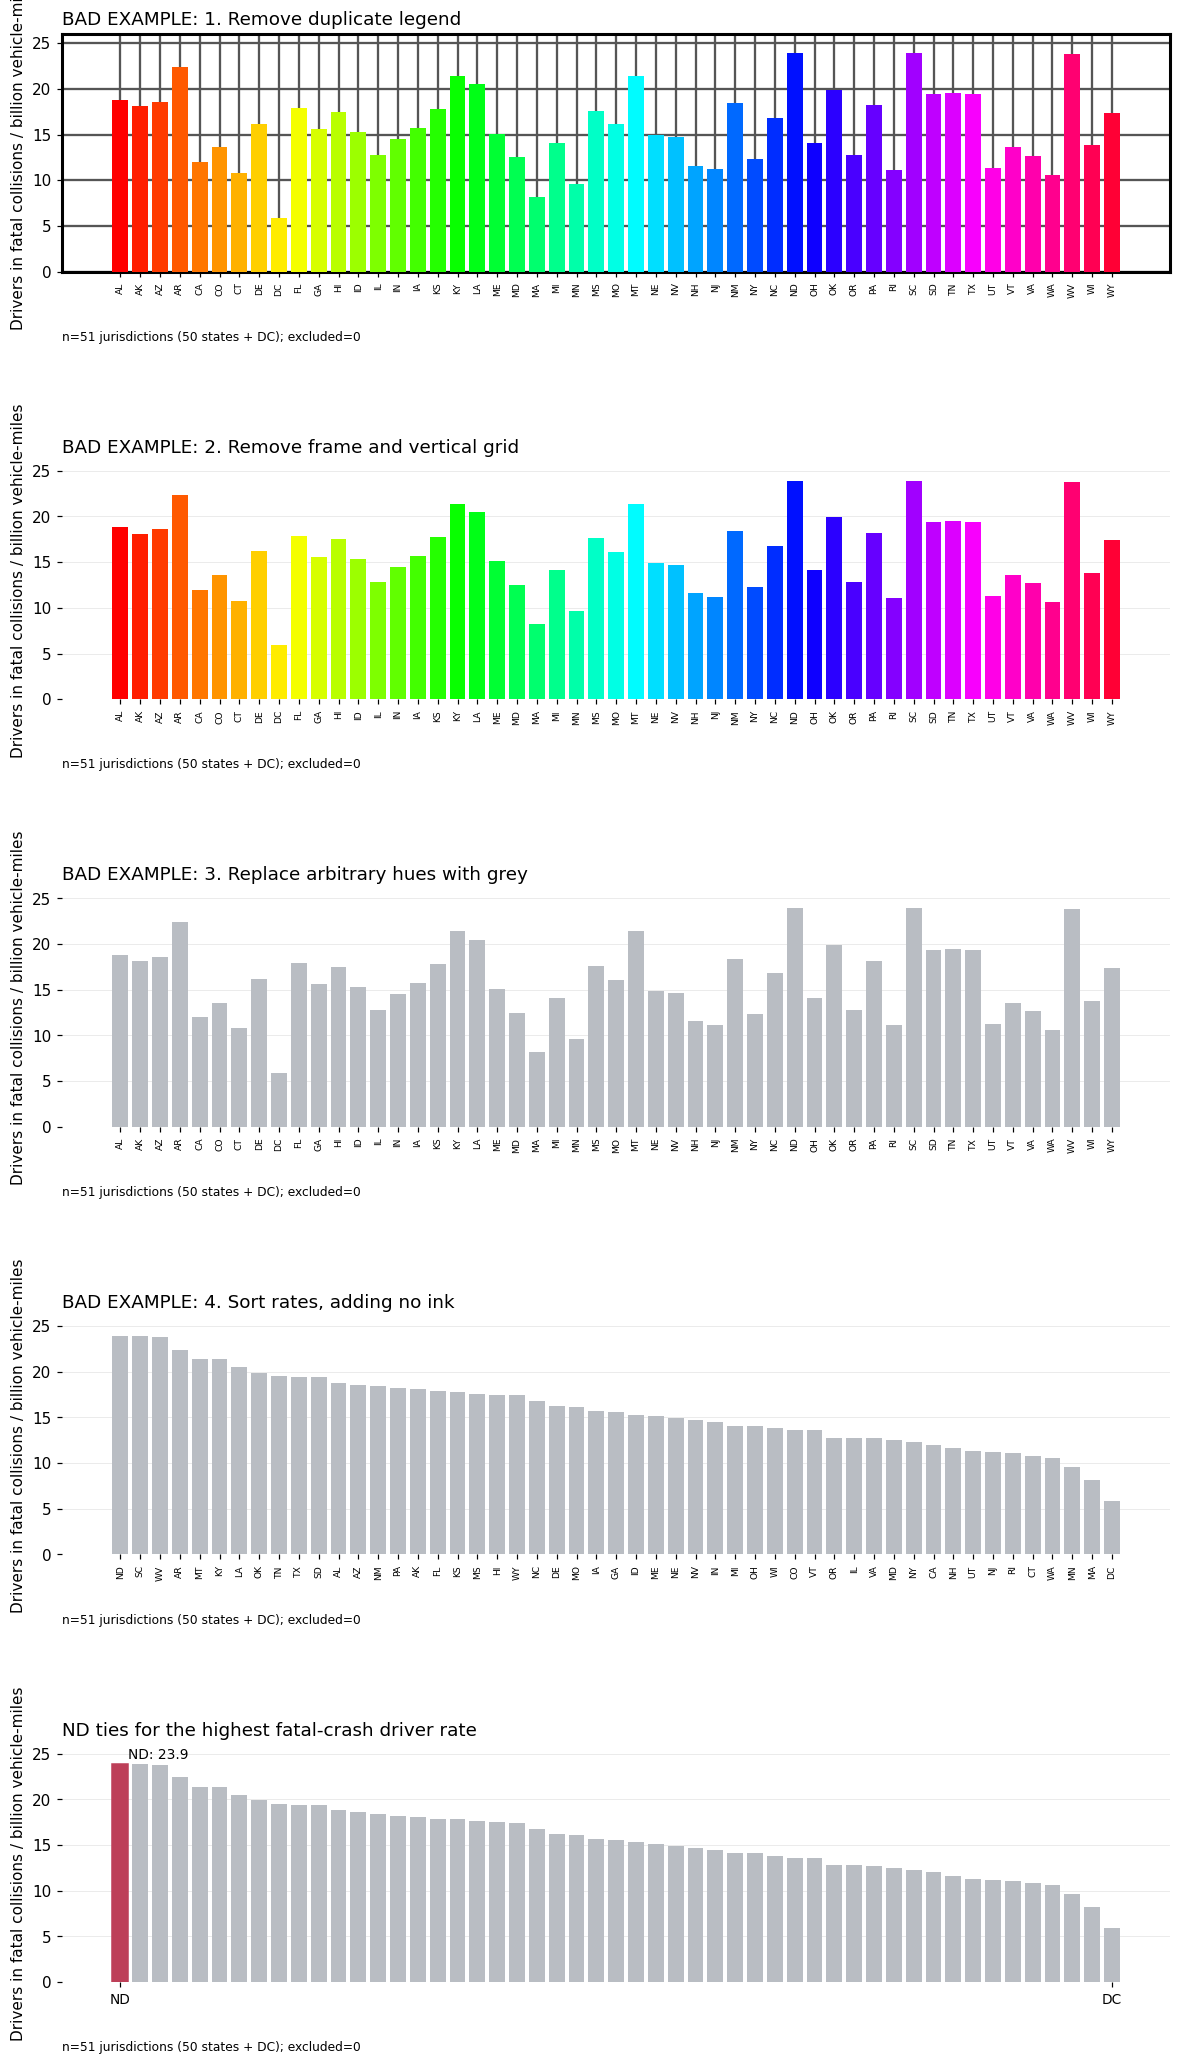

In [3]:
steps=['1. Remove duplicate legend','2. Remove frame and vertical grid','3. Replace arbitrary hues with grey','4. Sort rates, adding no ink','5. Label the maximum selectively']
fig,axes=plt.subplots(5,1,figsize=(13,23))
for stage,(ax,title) in enumerate(zip(axes,steps),1):
    crash_bars(ax,stage)
    ax.set_title('BAD EXAMPLE: '+title if stage<5 else f'{crashes.loc[crashes.total.idxmax(), "abbrev"]} ties for the highest fatal-crash driver rate',loc='left')
fig.subplots_adjust(hspace=.8);save(fig,'task3_five_steps.png');plt.show()


**Under panel 1:** removed 51 redundant handles and names (extraneous matching load); arbitrary colour remains deliberately bad. **Under panel 2:** removed four frame edges and 51 vertical gridlines; thinned horizontal guides (extraneous weight), preserving comparison aid. **Under panel 3:** removed 51 arbitrary hues (extraneous nominal decoding), using grey context. **Under panel 4:** sorted bars, removing mental ranking work without adding ink; identities and values remain. **Under panel 5:** removed 49 crowded tick labels, keeping maximum/minimum identities and adding a direct maximum value label. One maximum bar pops out using hue; length and the label also communicate it. Connection is not needed here; alignment and proximity pair each retained label with its bar. All panels keep all 51 values.

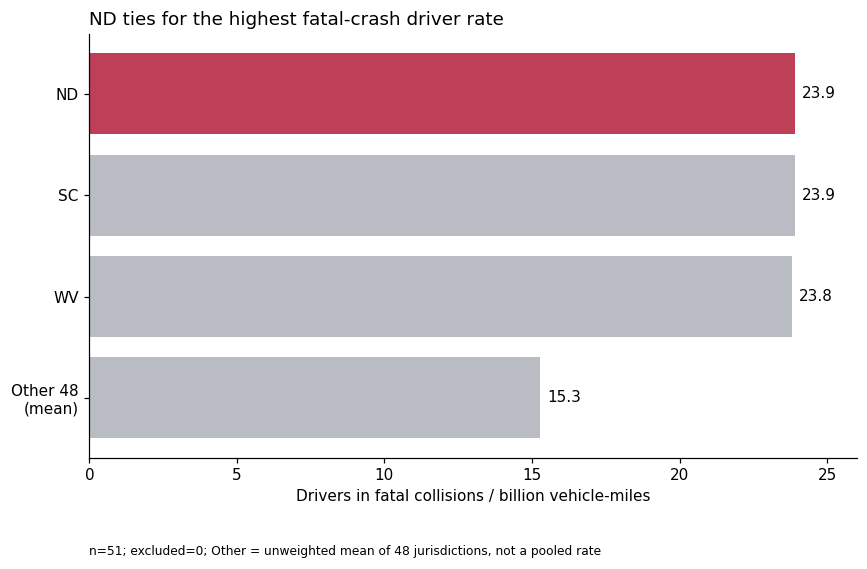

,label,rate
0,ND,23.900000
1,SC,23.900000
2,WV,23.800000
3,Other 48\n(mean),15.285417


In [4]:
ranked=crashes.sort_values('total',ascending=False)
top=ranked.head(3)
rest=ranked.iloc[3:]
chunk=pd.DataFrame({'label':list(top.abbrev)+['Other 48\n(mean)'],'rate':list(top.total)+[rest.total.mean()]})
fig,ax=plt.subplots(figsize=(9,5))
ax.barh(chunk.label,chunk.rate,color=[ACCENT,GREY,GREY,GREY]);ax.invert_yaxis();ax.set_xlim(0,26)
ax.set_xlabel('Drivers in fatal collisions / billion vehicle-miles');ax.set_title(f'{top.abbrev.iloc[0]} ties for the highest fatal-crash driver rate',loc='left')
for i,v in enumerate(chunk.rate):ax.text(v+.25,i,f'{v:.1f}',va='center')
clean(ax);ax.text(0,-.23,'n=51; excluded=0; Other = unweighted mean of 48 jurisdictions, not a pooled rate',transform=ax.transAxes,fontsize=8)
save(fig,'task3_four_chunks.png');plt.show();display(chunk)


**Four chunks:** three highest jurisdictions and the unweighted mean of the remaining 48. This is four displayed category chunks, not a claim about exactly how much a reader holds in memory. Position and zero-baseline length show quantitative rates; proximity associates direct labels, and one accent selects the maximum. Pooling rates into a sum would be invalid. This compact design hides the identities, spread and ordering of 48 jurisdictions; the full ranked plot remains available. DC is a jurisdiction, so “other 48 states” would be misleading.

ND and SC both have 23.9: ND shares the maximum rather than being uniquely highest. The highlight selects one co-maximum, while the SC value remains labelled.

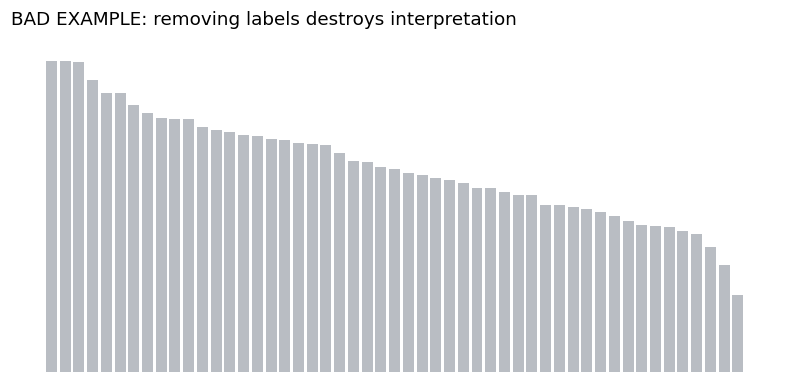

In [5]:
fig,ax=plt.subplots(figsize=(9,4));ax.bar(range(51),ranked.total,color=GREY);ax.set_ylim(0,26);ax.set_axis_off()
ax.set_title('BAD EXAMPLE: removing labels destroys interpretation',loc='left');save(fig,'task3_overstripped.png');plt.show()


**Too little ink:** lengths remain but units, jurisdiction identities and tick values disappear. Similarity makes the grey bars a set and sorted position hints at ranking, yet readers cannot retrieve a rate. No rows were removed. **Stopping rule:** remove an element only if a reader can still identify the variables, units, scope and intended comparison accurately without extra effort.

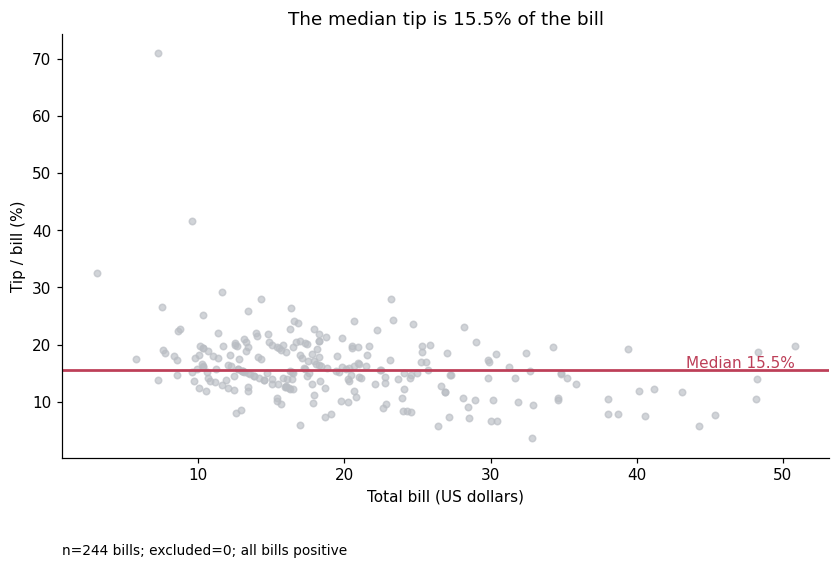

In [6]:
tips=pd.read_csv(DATA/'tips.csv'); percent=100*tips.tip/tips.total_bill
median=float(percent.median())
fig,ax=plt.subplots(figsize=(9,5));ax.scatter(tips.total_bill,percent,color=GREY,s=18,alpha=.65)
ax.axhline(median,color=ACCENT,lw=1.8)
ax.text(tips.total_bill.max(),median+.5,f'Median {median:.1f}%',ha='right',color=ACCENT)
ax.set(title=f'The median tip is {median:.1f}% of the bill',xlabel='Total bill (US dollars)',ylabel='Tip / bill (%)');clean(ax)
ax.text(0,-.23,'n=244 bills; excluded=0; all bills positive',transform=ax.transAxes,fontsize=9)
save(fig,'task3_helpful_ink.png');plt.show()


**Adding ink helps:** the reference line and direct label save readers estimating the median from 244 points. Position represents two quantitative variables; one accent reference line carries the title’s message, and its text communicates it without colour alone. Proximity pairs that label with the line. Similarity treats the grey observations as context. These germane additions reduce extraneous calculation effort, although they lower a simple data-ink fraction. The median is a median of bill-level percentages, not total tips divided by total bills.